<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/20_Blockchain_Attack_Detection/QRBM_EthereumAttack_Rajawat2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QRBM for Ethereum attack-vector classification: Rajawat et al. (2024) step by step

**Paper.** Anand Singh Rajawat, S. B. Goyal, Manoj Kumar, Saurabh Kumar, *Quantum Deep Neural Network Based Classification of Attack Vectors on the Ethereum Blockchain*, EAI Endorsed Transactions on Scalable Information Systems, vol. 11, no. 6, 2024. DOI [10.4108/eetsis.5572](https://doi.org/10.4108/eetsis.5572).

**What this notebook does.** The paper proposes a *Quantum Restricted Boltzmann Machine* (QRBM) that reads Ethereum data and outputs one of five labels: *no attack*, *reentrancy*, *phishing*, *underflow/overflow* or *gas limit*. It reports per-attack accuracy, precision, recall and F1 of 94-98 % (Tables 2 and 4) and says the QRBM beats GANs, RBF networks, MLPs, SOMs and DBNs. The paper does not publish its dataset, circuit, code or any hyper-parameter beyond "200 visible units, 100 hidden units, 100 000 epochs". This notebook therefore

1. downloads a **public substitute dataset** of Ethereum smart contracts labelled by the Slither static analyser (reentrancy, arithmetic, access-control, unchecked-calls, safe) and turns the deployed bytecode into opcode features,
2. builds a **QRBM from first principles**: a transverse-field quantum Boltzmann machine (qubits = hidden units + label units, exact thermal state, visible units clamped to the data), trained by gradient descent in PyTorch and cross-checked against Qiskit's Pauli operators,
3. trains the same machine with the transverse field switched off (its classical limit), a classical RBM, DBN, MLP, RBF network, SOM, SVC and random forest on identical inputs,
4. prints the paper's tables next to the notebook's numbers with a verdict per claim.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. Everything is downloaded inside the notebook (about 60 MB of Parquet columns streamed from Hugging Face). With `FAST_MODE = True` the whole notebook finishes in about 10 minutes; `FAST_MODE = False` uses larger samples, one more hidden qubit and three seeds (runtime is printed at the end).

**What you get at the end.** A working small QRBM, an honest side-by-side with the paper (several of its claims *cannot* be checked with public data, and the notebook says which), and a critical reading of what the paper does and does not show.

## The paper in one page

- **Problem.** Classify attack vectors on Ethereum: reentrancy, phishing, underflow/overflow and gas-limit attacks, plus normal behaviour.
- **Decision.** Multi-class; the output register is measured and mapped to a class ("|0> = no attack, |1> = reentrancy, |2> = phishing ...").
- **Method.** A Quantum Restricted Boltzmann Machine ("quantum deep neural network"): quantum visible and hidden units, quantum weights `W` and biases `a`, `b`, a "quantum sigmoid" built from gates, Gibbs sampling in quantum space, classical data embedded by amplitude embedding, trained by a "quantum-enhanced contrastive divergence". The text names Qiskit or TensorFlow Quantum as possible frameworks but does not say which one was used, and gives no circuit.
- **Data.** "Half a million transactions conducted on Ethereum", labelled with reentrancy, phishing, underflow, overflow and gas-limit attacks. Source, labelling procedure, features and class balance are not given.
- **Configuration.** 200 visible and 100 hidden quantum units, 100 000 epochs, "quantum mechanically optimised" learning rate. No train/test ratio, no seeds, no repetitions.
- **Claims.** Table 2: reentrancy 97/96/98/97 (accuracy/precision/recall/F1, %), phishing 94/93/95/94, underflow-overflow 96/95/96/95.5, gas limit 95/94/95/94.5, "classified correctly" 98/99/97/98. Text: QRBM averages 95 % against 92 % for a classical RBM. Table 4: QRBM beats GAN, RBFN, MLP, SOM and DBN on every attack vector (for example reentrancy accuracy 97 % against 90-95 %). The abstract also claims better scalability, speed and robustness to non-informative inputs.
- **Internal inconsistencies worth noting.** Table 2 and Table 4 give different QRBM numbers for the same attack (reentrancy recall 98 % vs 95 %; underflow-overflow accuracy 96 % vs 94 %), the algorithm box is partly garbled ("Bose-Einstein Condensator Quantum Monte Carlo Simulation (QRBM)"), the introduction calls the QRBM a "Quantum Recursive Backpropagation Neural Network", and no confusion matrix is given.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | ~500 000 Ethereum transactions, labelled reentrancy / phishing / underflow / overflow / gas limit; source not given | Public **Slither Audited Smart Contracts** dataset (Hugging Face `mwritescode/slither-audited-smart-contracts`, ~100 000 verified Ethereum mainnet contracts with deployed bytecode and Slither detector output). Contracts with exactly one label class are used. **Substitute**, not the paper's data |
| Attack classes | no attack, reentrancy, phishing, underflow/overflow, gas limit | no attack (`safe`), reentrancy, arithmetic (closest to underflow/overflow: Slither's `divide-before-multiply`), access-control, unchecked-calls. **Phishing and gas limit have no counterpart** in this dataset and cannot be checked; access-control and unchecked-calls fill the 4th and 5th class so that the task is still 5-way |
| Unit of classification | a transaction / contract-call pattern | a deployed contract (opcode statistics of its bytecode) |
| Features | amplitude-embedded transaction state, not specified | opcode histogram (256 bins) + 3 pattern counts (CALL followed by SSTORE, DIV followed by MUL, log length); scaled, `SelectKBest`, `PCA`, thermometer bits (`# CHOICE:` in code) |
| Model | QRBM, 200 visible / 100 hidden quantum units | Transverse-field **quantum Boltzmann machine**: 32 clamped visible bits (16 PCA components x 2 thermometer bits), 3-4 hidden qubits, 3 label qubits (binary code of the class), exact thermal state. Scaled down by orders of magnitude because the thermal state is simulated exactly |
| Quantum "sigmoid", Gibbs sampling, amplitude embedding | named, not specified | Replaced by the exact Gibbs state `exp(-H)/Z`, which is what an ideal quantum Gibbs sampler would produce. Visible units are classical bits that set the local fields (the clamped Hamiltonian of a quantum Boltzmann machine) |
| Training | quantum-enhanced contrastive divergence, 100 000 epochs | **Discriminative** maximum likelihood of `P(class | data)` with Adam on the exact gradient (autograd through `eigh`), 200-400 steps, mini-batches; best step chosen on a validation split of the training data |
| Learning rate, batch size, seeds, split | not reported | `# CHOICE:` lr 0.05, batch 48/64, seeds 42-44, stratified 70/30 split |
| Classical RBM baseline | "92 % average accuracy", unspecified | scikit-learn `BernoulliRBM` + logistic regression on the same bits, and the QRBM with the transverse field set to zero (its exact classical limit) |
| GAN, RBFN, MLP, SOM, DBN baselines (Table 4) | numbers only | MLP, RBFN, SOM and DBN are rebuilt on the same inputs; **GAN is not rebuilt** (a GAN is a generative model and the paper gives no classifier) |
| Metrics | accuracy, precision, recall, F1 per attack vector | one-vs-rest accuracy, precision, recall, F1 per class (the paper does not say how a 5-way problem yields a per-vector "accuracy"; OvR is the usual reading), plus 5-way accuracy and macro scores |
| Hardware | none (simulation implied) | exact classical simulation; `IBM_TOKEN` is accepted but nothing runs on hardware |

In [1]:
# Installs. Colab already ships numpy, pandas, scikit-learn, matplotlib, seaborn, torch and pyarrow.
# Qiskit is used only to cross-check the Hamiltonian (section 6); pins are the versions this notebook was tested with.
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
need = []
if IN_COLAB or importlib.util.find_spec("qiskit") is None:
    need += ["qiskit==2.5.2"]
if importlib.util.find_spec("pyarrow") is None:
    need += ["pyarrow"]
if importlib.util.find_spec("huggingface_hub") is None:
    need += ["huggingface_hub"]
if importlib.util.find_spec("torch") is None:
    need += ["torch"]                 # CPU build is enough
if need:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *need], check=False)
    print("installed:", need, "(restart the runtime if an import below fails)")
else:
    print("nothing to install")

nothing to install


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = False          # True: small budgets, whole notebook in about 10 minutes; False: full budgets
IBM_TOKEN = ""              # unused: no cell here runs on quantum hardware
DATA_DIR = "qrbm_eth_data"  # downloaded / cached data
HF_REPO = "mwritescode/slither-audited-smart-contracts"      # public substitute dataset (CHOICE)
SHARDS = [0] if FAST_MODE else [0, 1]                        # 15 000 contracts per raw shard

CLASSES = ["safe", "reentrancy", "arithmetic", "access-control", "unchecked-calls"]       # CHOICE: 5-way like the paper
CLASS_NAMES = ["No attack", "Reentrancy", "Underflow/overflow (arithmetic)", "Access control", "Unchecked calls"]
POOL_PER_CLASS = 450                                         # contracts kept per class in the cached pool
N_PER_CLASS = 150 if FAST_MODE else 400                      # contracts used per class (capped by the smallest class)
TEST_SIZE = 0.30                                             # stratified hold-out
VAL_FRAC = 0.15                                              # part of the training split used to pick the best training step

N_SELECT = 60               # SelectKBest(f_classif) features kept
N_PCA = 16                  # PCA components
BITS_PER_COMP = 2           # thermometer bits per component (-> 32 visible units)
N_HIDDEN = 3 if FAST_MODE else 4        # hidden qubits (+ 3 label qubits)
GAMMA_INIT = 0.5            # transverse field Gamma at the start of training
STEPS = 200 if FAST_MODE else 400       # Adam steps (the paper: 100 000 epochs)
BATCH = 48 if FAST_MODE else 64
LR = 0.05
EVAL_EVERY = 20 if FAST_MODE else 25
SEEDS = [42] if FAST_MODE else [42, 43, 44]     # repeated runs (mean +/- std in the tables)

In [3]:
import os, time, json, warnings, math, itertools
T0 = time.time()                      # wall clock of the whole run, printed at the end
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier, BernoulliRBM
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
warnings.filterwarnings("ignore")

np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

import qiskit
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__, "| qiskit", qiskit.__version__)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | qiskit 2.5.2


## 1. Data: Ethereum smart contracts labelled by Slither

The paper's half-million transactions are not available, and no public dataset labels Ethereum data with exactly its five classes. The closest public, large and multi-class resource is the **Slither Audited Smart Contracts** dataset (M. Rossini, 2022): about 100 000 contracts verified on Etherscan, with their deployed **bytecode** (fetched from the chain) and the output of the Slither static analyser, which the authors map to vulnerability classes after the DASP top-10. We read only the `contracts`, `bytecode` and `results` columns of the Parquet shards (the `source_code` column is most of the file size) straight from Hugging Face, so a shard costs a few seconds, not 200 MB.

Labels follow the dataset's own `label_mappings.json`. A contract is kept only if it falls in **exactly one** class (`safe` = no relevant detector fired); contracts flagged with several classes are dropped so that every row has a single, unambiguous label, as in the paper's one-label-per-sample setting.

Two honest caveats about the substitution:

- **Slither's `arithmetic` class is `divide-before-multiply`** (precision loss), not integer overflow or underflow, which Slither does not report in its default detector set. It is the nearest available label to the paper's "underflow and overflow" and should be read as a proxy.
- **No class stands for phishing or gas-limit attacks.** `access-control` (for example `tx.origin`, unprotected `selfdestruct`) and `unchecked-calls` take their places so that the problem stays five-way. Accuracies are therefore *not* comparable one-to-one with the paper's per-attack numbers, only in magnitude.

In [4]:
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem, hf_hub_download

mapping_path = hf_hub_download(HF_REPO, "data/label_mappings.json", repo_type="dataset", local_dir=DATA_DIR)
LABEL_MAP = json.load(open(mapping_path))

def slither_to_class(results_json):
    # Same rule as the dataset loader: map detectors to DASP classes, drop 'ignore', empty -> 'safe'
    r = json.loads(results_json)
    if not r.get("results"):
        return ("safe",)
    cls = {LABEL_MAP[d["check"]] for d in r["results"]["detectors"]} - {"ignore"}
    return tuple(sorted(cls)) or ("safe",)

def read_shard(i):
    # Stream only three columns of one raw shard; fall back to downloading the whole shard if streaming fails
    cols = ["contracts", "bytecode", "results"]
    try:
        with HfFileSystem().open(f"datasets/{HF_REPO}/data/raw/contracts{i}.parquet", "rb") as f:
            return pq.ParquetFile(f).read(columns=cols).to_pandas()
    except Exception as e:
        print("streaming failed (", type(e).__name__, "), downloading the whole shard instead")
        p = hf_hub_download(HF_REPO, f"data/raw/contracts{i}.parquet", repo_type="dataset", local_dir=DATA_DIR)
        return pq.read_table(p, columns=cols).to_pandas()

pool_path = os.path.join(DATA_DIR, f"pool_{'-'.join(map(str, SHARDS))}_{POOL_PER_CLASS}.parquet")
if os.path.exists(pool_path):
    pool = pd.read_parquet(pool_path)
    print("loaded cached pool:", pool_path)
else:
    parts = []
    for i in SHARDS:
        t0 = time.time(); df = read_shard(i)
        df = df[df.bytecode.str.len() > 200].copy()                 # drop contracts whose bytecode could not be fetched ('0x')
        df["classes"] = df.results.map(slither_to_class)
        df = df[df.classes.map(len) == 1]                            # exactly one label class
        df["label"] = df.classes.map(lambda t: t[0])
        parts.append(df[df.label.isin(CLASSES)][["contracts", "bytecode", "label"]])
        print(f"shard {i}: {time.time()-t0:.1f} s")
    full = pd.concat(parts, ignore_index=True).drop_duplicates("bytecode")   # identical bytecode = clones: keep one
    pool = pd.concat([full[full.label == c].sample(min((full.label == c).sum(), POOL_PER_CLASS), random_state=SEED) for c in CLASSES],
                     ignore_index=True)
    pool.to_parquet(pool_path)
    print("saved pool:", pool_path)

counts = pool.label.value_counts().reindex(CLASSES)
print(counts.to_string())

loaded cached pool: qrbm_eth_data\pool_0-1_450.parquet
label
safe               450
reentrancy         450
arithmetic         450
access-control     450
unchecked-calls    450


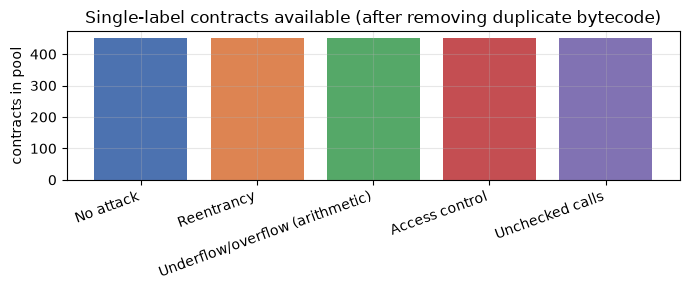

contracts used per class: 400 (requested 400, smallest class 450)


In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(CLASS_NAMES, counts.values, color=sns.color_palette("deep", 5))
ax.set_ylabel("contracts in pool"); ax.set_title("Single-label contracts available (after removing duplicate bytecode)")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
N_USE = int(min(N_PER_CLASS, counts.min()))
print(f"contracts used per class: {N_USE} (requested {N_PER_CLASS}, smallest class {int(counts.min())})")

## 2. From bytecode to numbers: opcode statistics

The paper quantum-encodes "a transaction" but never says which numbers describe it. For a deployed contract the most direct low-level description is its **EVM bytecode**. We disassemble it (skipping the data bytes that follow `PUSH1`..`PUSH32`, and cutting off the trailing compiler metadata) and take

- the normalised **histogram of the 256 opcode values** (for example how often `SSTORE`, `CALL` or `DIV` occur),
- three **pattern counts** that mirror the vulnerabilities: `CALL` followed by an `SSTORE` within 60 instructions (state written after an external call is the reentrancy pattern), `DIV` followed by `MUL` within 12 instructions (divide-before-multiply), and the log-length of the program.

This is a `# CHOICE:`; it is a weak proxy, because Slither labels come from *source code* while we only see compiled bytecode. Expect good but not perfect accuracy.

In [6]:
def disassemble(hexcode):
    # Return the list of opcode values of a runtime bytecode string, skipping PUSH data and trailing metadata
    b = bytes.fromhex(hexcode[2:] if hexcode.startswith("0x") else hexcode)
    if len(b) > 2:
        meta = int.from_bytes(b[-2:], "big")                   # solc appends CBOR metadata, length in the last 2 bytes
        if 0 < meta < len(b) - 2:
            b = b[:-(meta + 2)]
    ops, i, n = [], 0, len(b)
    while i < n:
        op = b[i]; ops.append(op)
        i += 1 + (op - 0x5F if 0x60 <= op <= 0x7F else 0)
    return np.array(ops, dtype=np.int16)

def next_within(pos_a, pos_b, w):
    # number of positions in pos_a that have an element of pos_b in the next w instructions
    if len(pos_a) == 0 or len(pos_b) == 0:
        return 0
    j = np.searchsorted(pos_b, pos_a, side="right")
    ok = j < len(pos_b)
    return int(np.sum(pos_b[j[ok]] - pos_a[ok] <= w))

def opcode_features(hexcode):
    ops = disassemble(hexcode); n = max(len(ops), 1)
    hist = np.bincount(ops, minlength=256)[:256] / n
    call, sstore = np.where(ops == 0xF1)[0], np.where(ops == 0x55)[0]
    div, mul = np.where(ops == 0x04)[0], np.where(ops == 0x02)[0]
    return np.concatenate([hist, [next_within(call, sstore, 60) / n, next_within(div, mul, 12) / n, np.log10(n)]])

OPNAMES = {0x01: "ADD", 0x02: "MUL", 0x03: "SUB", 0x04: "DIV", 0x10: "LT", 0x11: "GT", 0x14: "EQ", 0x15: "ISZERO", 0x20: "SHA3",
           0x32: "ORIGIN", 0x33: "CALLER", 0x34: "CALLVALUE", 0x35: "CALLDATALOAD", 0x3B: "EXTCODESIZE", 0x54: "SLOAD", 0x55: "SSTORE",
           0x56: "JUMP", 0x57: "JUMPI", 0x5A: "GAS", 0xF1: "CALL", 0xF3: "RETURN", 0xF4: "DELEGATECALL", 0xFA: "STATICCALL",
           0xFD: "REVERT", 0xFE: "INVALID", 0xFF: "SELFDESTRUCT", 0x63: "PUSH4"}
FEATURE_NAMES = [OPNAMES.get(i, f"op{i:02x}") for i in range(256)] + ["CALL->SSTORE", "DIV->MUL", "log_len"]

example = pool.iloc[0]
ops = disassemble(example.bytecode)
print("example contract", example.contracts, "| label:", example.label, "| instructions:", len(ops))
print("first 12 opcodes:", [OPNAMES.get(int(o), hex(int(o))) for o in ops[:12]])

example contract 02a89330e27675bf50bb32833e4e430056aef504 | label: safe | instructions: 896
first 12 opcodes: ['0x60', '0x60', '0x52', '0x60', '0x36', 'LT', '0x61', 'JUMPI', 'PUSH4', '0x7c', '0x60', 'CALLDATALOAD']


feature matrix: (2250, 259)


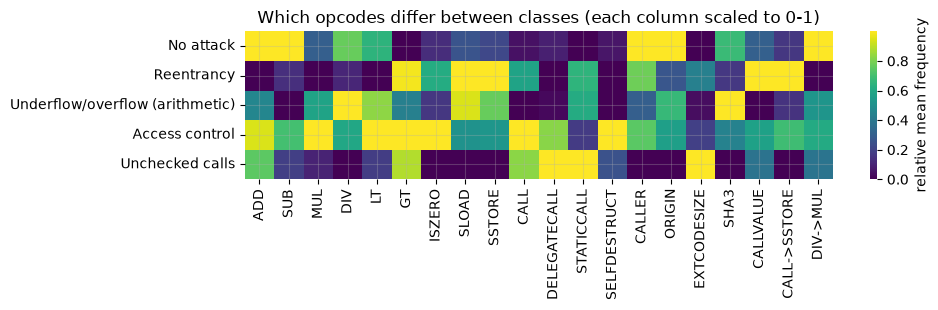

In [7]:
feat_path = os.path.join(DATA_DIR, f"features_{os.path.basename(pool_path)}.npy")
if os.path.exists(feat_path):
    F_pool = np.load(feat_path)
else:
    t0 = time.time()
    F_pool = np.vstack([opcode_features(h) for h in pool.bytecode])
    np.save(feat_path, F_pool)
    print(f"disassembled {len(pool)} contracts in {time.time()-t0:.0f} s")
y_pool = pool.label.map({c: i for i, c in enumerate(CLASSES)}).values
print("feature matrix:", F_pool.shape)

# mean frequency of selected opcodes per class (column-normalised heat map)
show = ["ADD", "SUB", "MUL", "DIV", "LT", "GT", "ISZERO", "SLOAD", "SSTORE", "CALL", "DELEGATECALL", "STATICCALL", "SELFDESTRUCT",
        "CALLER", "ORIGIN", "EXTCODESIZE", "SHA3", "CALLVALUE", "CALL->SSTORE", "DIV->MUL"]
M = np.array([F_pool[y_pool == k][:, [FEATURE_NAMES.index(s) for s in show]].mean(0) for k in range(5)])
M = (M - M.min(0)) / (M.max(0) - M.min(0) + 1e-12)
plt.figure(figsize=(10, 3.2))
sns.heatmap(pd.DataFrame(M, index=CLASS_NAMES, columns=show), cmap="viridis", cbar_kws={"label": "relative mean frequency"})
plt.title("Which opcodes differ between classes (each column scaled to 0-1)"); plt.tight_layout(); plt.show()

## 3. Split and preprocessing (everything fitted on the training split only)

For each seed we draw `N_USE` contracts per class from the pool, make a stratified 70/30 split, and fit the following chain **on the training part only**:

`log1p scaling -> drop constant columns -> StandardScaler -> SelectKBest(f_classif) -> PCA(16) -> StandardScaler`.

The 16 standardised components are the **inputs of the classical baselines**. The **quantum and RBM-type models need binary visible units**, so each component is turned into two *thermometer bits* (`x > t1`, `x > t2`, with `t1`, `t2` the 33rd and 67th training percentiles), giving 32 visible bits. The test set uses the training thresholds.

A further 15 % of the training data is set aside as a **validation set** that the QRBM uses only to choose the best training step.

In [8]:
def make_split(seed):
    # Balanced sample of N_USE contracts per class, stratified train/test split
    r = np.random.default_rng(seed)
    idx = np.concatenate([r.choice(np.where(y_pool == k)[0], N_USE, replace=False) for k in range(5)])
    return train_test_split(F_pool[idx], y_pool[idx], test_size=TEST_SIZE, stratify=y_pool[idx], random_state=seed)

class Preprocessor:
    # log1p -> VarianceThreshold -> StandardScaler -> SelectKBest -> PCA -> StandardScaler, then thermometer bits
    def fit(self, X, y, seed):
        Z = np.log1p(1000 * np.clip(X, 0, None))
        self.vt = VarianceThreshold(1e-8).fit(Z); Z = self.vt.transform(Z)
        self.sc1 = StandardScaler().fit(Z); Z = self.sc1.transform(Z)
        self.sel = SelectKBest(f_classif, k=min(N_SELECT, Z.shape[1])).fit(Z, y); Z = self.sel.transform(Z)
        self.pca = PCA(n_components=N_PCA, random_state=seed).fit(Z); Z = self.pca.transform(Z)
        self.sc2 = StandardScaler().fit(Z); Z = self.sc2.transform(Z)
        qs = np.linspace(0, 1, BITS_PER_COMP + 2)[1:-1]            # 33rd and 67th percentile
        self.thr = np.quantile(Z, qs, axis=0)                      # (BITS_PER_COMP, N_PCA), training data only
        return self
    def comps(self, X):
        Z = np.log1p(1000 * np.clip(X, 0, None))
        return self.sc2.transform(self.pca.transform(self.sel.transform(self.sc1.transform(self.vt.transform(Z)))))
    def bits(self, X):
        Z = self.comps(X)
        return np.concatenate([(Z > t).astype(np.float64) for t in self.thr], axis=1)

Xtr_raw, Xte_raw, ytr, yte = make_split(SEED)
pre = Preprocessor().fit(Xtr_raw, ytr, SEED)
print("train", Xtr_raw.shape, "test", Xte_raw.shape, "| components", pre.comps(Xtr_raw).shape, "| visible bits", pre.bits(Xtr_raw).shape)
print("class counts train:", np.bincount(ytr), "test:", np.bincount(yte))

train (1400, 259) test (600, 259) | components (1400, 16) | visible bits (1400, 32)
class counts train: [280 280 280 280 280] test: [120 120 120 120 120]


## 4. The model: a quantum restricted Boltzmann machine

**Classical RBM in one paragraph.** An RBM has visible units `v` (the data) and hidden units `h`, with energy `E(v,h) = -sum b_i v_i - sum c_j h_j - sum W_ij v_i h_j` and probability `P(v,h) ~ exp(-E)`. There are no visible-visible or hidden-hidden connections ("restricted"). For classification the label is added as extra units `y` connected to the hidden units (a *discriminative RBM*), and the prediction is the label with the largest `P(y | v)`.

**The quantum version.** Replace every unit that is not clamped by a **qubit** and the energy function by a **Hamiltonian**; the model state is the thermal (Gibbs) state `rho = exp(-H) / Tr exp(-H)`. We use the standard *transverse-field* Hamiltonian of a quantum Boltzmann machine (Amin et al., 2018):

`H(v) = - sum_j f_j(v) Z_j  -  sum_k d_k Z_k^y  -  sum_{j,k} V_jk Z_j Z_k^y  -  Gamma_h sum_j X_j  -  Gamma_y sum_k X_k^y`, with local fields `f_j(v) = c_j + sum_i W_ij v_i`.

`Z` and `X` are Pauli operators. The first three terms are the classical RBM (the visible bits only enter through the fields `f_j(v)`, which is exactly what clamping them to a computational basis state does); the last two terms are the **transverse field** that makes the model quantum: it does not commute with the rest, so the thermal state has coherences and the hidden/label qubits can be entangled in ways no classical RBM reproduces.

**Reading out a class.** The label register has `ceil(log2 5) = 3` qubits holding the binary code of the class. The model's class probability is the probability of measuring that code in the label register of `rho`, renormalised over the five valid codes:

`P(y = k | v) = sum_h <k,h| rho(v) |k,h>  /  sum_{k'} sum_h <k',h| rho(v) |k',h>`.

This is the paper's "measure the state of the output and map the outcome to an attack type".

**Training.** We maximise `log P(y | v)` with Adam. The gradient is obtained by automatic differentiation through the exact eigendecomposition of `H` (a 2^n x 2^n matrix, n = hidden + 3 qubits, so 64 or 128 dimensions). The paper's "quantum-enhanced contrastive divergence" is a *generative* rule that needs a quantum sampler; we replace it by this exact, discriminative objective, which is what such a sampler would approximate.

**Setting `Gamma = 0`** makes `H` diagonal, `rho` classical, and the model a plain (binary-coded) discriminative RBM. That is the fair "same model, no quantum effect" baseline used below.

**The exact Gibbs state and its gradient.** For a Hamiltonian `H = U diag(w) U^T` the diagonal of `rho = exp(-H)/Z` in the computational basis is `p_s = sum_k U_sk^2 exp(-w_k) / Z`. Differentiating through `eigh` is numerically unstable when eigenvalues are (almost) degenerate, which happens here whenever the fields are small, so the backward pass below uses the exact Duhamel formula for the derivative of a matrix exponential, `d tr(G e^{-H}) = -tr(G * integral_0^1 e^{-sH} dH e^{-(1-s)H} ds)`, whose eigenbasis kernel `(e^{-w_l} - e^{-w_k}) / (w_k - w_l)` has a smooth limit when `w_k = w_l`. The cell below defines it and checks it against autograd through `torch.linalg.matrix_exp`.

In [9]:
class ThermalDiag(torch.autograd.Function):
    # p = diag(exp(-H)) / Tr exp(-H) for a batch of real symmetric H, with a degeneracy-safe backward pass
    @staticmethod
    def forward(ctx, H):
        w, U = torch.linalg.eigh(H)
        w = w - w.min(dim=-1, keepdim=True).values                        # shift: p is invariant, exp stays <= 1
        e = torch.exp(-w); Z = e.sum(-1, keepdim=True)
        p = ((U ** 2) * e[:, None, :]).sum(-1) / Z
        ctx.save_for_backward(w, U, Z, p)
        return p
    @staticmethod
    def backward(ctx, gp):
        w, U, Z, p = ctx.saved_tensors
        g = (gp - (gp * p).sum(-1, keepdim=True)) / Z                      # dL/d rho~_ss, rho~ = exp(-H) (unnormalised)
        delta = (w[:, :, None] - w[:, None, :]) / 2
        small = delta.abs() < 1e-6
        ds = torch.where(small, torch.ones_like(delta), delta)
        sinhc = torch.where(small, 1 + delta ** 2 / 6, torch.sinh(ds) / ds)
        Phi = torch.exp(-(w[:, :, None] + w[:, None, :]) / 2) * sinhc        # (e^{-w_l} - e^{-w_k}) / (w_k - w_l), smooth at w_k = w_l
        Gt = torch.einsum("bsk,bs,bsl->bkl", U, g, U)                       # U^T diag(g) U
        return -torch.einsum("bsk,bkl,btl->bst", U, Gt * Phi, U)

# gradient check against autograd through the matrix exponential, including an exactly degenerate H
torch.manual_seed(0)
A = torch.randn(3, 16, 16, dtype=torch.float64); A = ((A + A.transpose(1, 2)) / 2).requires_grad_(True)
weights = torch.randn(3, 16, dtype=torch.float64)
def p_ref(H):
    R = torch.linalg.matrix_exp(-H); return torch.diagonal(R, dim1=1, dim2=2) / torch.diagonal(R, dim1=1, dim2=2).sum(-1, keepdim=True)
g_ref, = torch.autograd.grad((p_ref(A) * weights).sum(), A)
g_new, = torch.autograd.grad((ThermalDiag.apply(A) * weights).sum(), A)
print("custom gradient == matrix_exp autograd:", torch.allclose(g_ref, g_new, atol=1e-9), "| max diff", float((g_ref - g_new).abs().max()))
Hd = torch.diag_embed(torch.tensor([[0.0, 0.0, 1.0, 1.0] * 4], dtype=torch.float64)).requires_grad_(True)       # degenerate spectrum
gd, = torch.autograd.grad((ThermalDiag.apply(Hd) * weights[:1]).sum(), Hd)
print("finite gradient for a fully degenerate H:", bool(torch.isfinite(gd).all()))

custom gradient == matrix_exp autograd: True | max diff 3.608224830031759e-16
finite gradient for a fully degenerate H: True


In [10]:
class QRBM(torch.nn.Module):
    # Transverse-field quantum Boltzmann machine with clamped visible bits (see the text above)
    def __init__(self, n_vis, n_hid, n_cls, seed, quantum=True, gamma0=0.5):
        super().__init__()
        self.nh, self.nl, self.K, self.quantum = n_hid, int(math.ceil(math.log2(n_cls))), n_cls, quantum
        n = self.nh + self.nl; D = 2 ** n; self.n, self.D = n, D
        g = torch.Generator().manual_seed(seed)
        self.W = torch.nn.Parameter(0.05 * torch.randn(n_vis, n_hid, generator=g, dtype=torch.float64))   # CHOICE: small random init
        self.c = torch.nn.Parameter(torch.zeros(n_hid, dtype=torch.float64))
        self.V = torch.nn.Parameter(0.3 * torch.randn(n_hid, self.nl, generator=g, dtype=torch.float64))
        self.d = torch.nn.Parameter(torch.zeros(self.nl, dtype=torch.float64))
        inv = math.log(math.exp(gamma0) - 1)                                 # inverse softplus
        self.raw_gamma = torch.nn.Parameter(torch.tensor([inv, inv], dtype=torch.float64))   # (hidden, label) transverse fields
        s = torch.arange(D)
        z = torch.stack([1.0 - 2.0 * ((s >> i) & 1).double() for i in range(n)])       # (n, D): Z_i eigenvalues, qubit i = bit i
        self.register_buffer("z", z)
        def xsum(qs):
            X = torch.zeros(D, D, dtype=torch.float64)
            for i in qs:
                X[s, s ^ (1 << i)] += 1.0
            return X
        self.register_buffer("Xh", xsum(range(self.nh)))                    # sum of X_i over hidden qubits
        self.register_buffer("Xy", xsum(range(self.nh, n)))                 # sum of X_i over label qubits

    def gamma(self):
        return torch.nn.functional.softplus(self.raw_gamma)

    def hamiltonian(self, v, gamma=None):
        f = self.c + v @ self.W                                              # (B, nh) local fields of the hidden qubits
        zh, zy = self.z[:self.nh], self.z[self.nh:]
        E = -(f @ zh) - (self.d @ zy) - torch.einsum("jk,js,ks->s", self.V, zh, zy)[None, :]      # diagonal part (B, D)
        return E

    def class_logprob(self, v, quantum=None):
        quantum = self.quantum if quantum is None else quantum
        E = self.hamiltonian(v)
        if quantum:
            g = self.gamma()
            H = torch.diag_embed(E) - (g[0] * self.Xh + g[1] * self.Xy)[None]
            p = ThermalDiag.apply(H)                                         # diagonal of rho = exp(-H)/Z
        else:
            p = torch.softmax(-E, dim=-1)                                    # Gamma = 0: rho is diagonal
        pk = p.reshape(-1, 2 ** self.nl, 2 ** self.nh).sum(-1)[:, :self.K]    # label-register probabilities of valid codes
        return torch.log(pk / pk.sum(-1, keepdim=True))

    @torch.no_grad()
    def predict_proba(self, V, quantum=None, chunk=128):
        V = np.asarray(V, dtype=np.float64)
        uniq, inv = np.unique(V, axis=0, return_inverse=True)                # identical bit patterns share one thermal state
        out = np.vstack([self.class_logprob(torch.from_numpy(uniq[i:i + chunk]), quantum).exp().numpy()
                         for i in range(0, len(uniq), chunk)])
        return out[inv.reshape(-1)]

    def predict(self, V, quantum=None):
        return self.predict_proba(V, quantum).argmax(1)

m = QRBM(32, N_HIDDEN, 5, SEED, gamma0=GAMMA_INIT)
print(f"qubits: {m.nh} hidden + {m.nl} label = {m.n}  (Hilbert space {m.D}) | parameters: {sum(p.numel() for p in m.parameters())}")

qubits: 4 hidden + 3 label = 7  (Hilbert space 128) | parameters: 149


## 5. Checking the Hamiltonian against Qiskit

The tensor code above builds `H` from index arithmetic. To make sure it really is the operator written in section 4 we rebuild the same Hamiltonian for one data point as a Qiskit `SparsePauliOp` (Pauli strings `Z`, `ZZ`, `X`, qubit `i` = bit `i`, Qiskit's little-endian convention) and compare the dense matrices and the resulting class probabilities (via `scipy.linalg.expm`). This is the "gate for gate" check: no circuit is in the paper, so the operator is what we can verify.

In [11]:
from qiskit.quantum_info import SparsePauliOp
from scipy.linalg import expm

def qiskit_hamiltonian(model, v):
    n, nh = model.n, model.nh
    f = (model.c + torch.from_numpy(v) @ model.W).detach().numpy()
    g = model.gamma().detach().numpy(); d = model.d.detach().numpy(); Vw = model.V.detach().numpy()
    terms = []
    for j in range(nh):
        terms.append(("Z", [j], -f[j])); terms.append(("X", [j], -g[0]))
    for k in range(model.nl):
        terms.append(("Z", [nh + k], -d[k])); terms.append(("X", [nh + k], -g[1]))
        for j in range(nh):
            terms.append(("ZZ", [j, nh + k], -Vw[j, k]))
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n)

# check on an untrained and a perturbed model
torch.manual_seed(0)
mc = QRBM(32, N_HIDDEN, 5, 7, gamma0=0.7)
with torch.no_grad():
    mc.W += 0.3 * torch.randn_like(mc.W); mc.c += 0.2 * torch.randn_like(mc.c); mc.d += 0.2 * torch.randn_like(mc.d)
v0 = pre.bits(Xtr_raw[:1])
H_t = (torch.diag_embed(mc.hamiltonian(torch.from_numpy(v0))) - (mc.gamma()[0] * mc.Xh + mc.gamma()[1] * mc.Xy)[None])[0].detach().numpy()
H_q = qiskit_hamiltonian(mc, v0[0]).to_matrix()
print("Hamiltonian matches the Qiskit SparsePauliOp:", np.allclose(H_t, H_q))
rho = expm(-H_q); rho /= np.trace(rho)
p_q = np.real(np.diag(rho)).reshape(2 ** mc.nl, 2 ** mc.nh).sum(1)[:5]; p_q /= p_q.sum()
p_t = mc.predict_proba(v0)[0]
print("class probabilities, torch eigh :", np.round(p_t, 4))
print("class probabilities, Qiskit+expm:", np.round(p_q, 4), "| agree:", np.allclose(p_t, p_q))

Hamiltonian matches the Qiskit SparsePauliOp:

 True
class probabilities, torch eigh : [0.1296 0.182  0.159  0.3541 0.1752]
class probabilities, Qiskit+expm: [0.1296 0.182  0.159  0.3541 0.1752] | agree: True


## 6. Training the QRBM

Mini-batches of `BATCH` training contracts, Adam with learning rate `LR`, `STEPS` steps. Every `EVAL_EVERY` steps the validation negative log-likelihood is computed; the parameters of the **best validation step** are restored at the end (the validation set is a slice of the training split, never the test set). For comparison the identical machine with the transverse field removed (`quantum=False`) is trained with the same recipe.

A word on size. The paper trains 200 + 100 units for 100 000 epochs. Here the thermal state of `hidden + 3` qubits is simulated exactly, which costs time `O(8^n)` per data point and step; 3-4 hidden qubits and 200-400 steps are what a CPU does in minutes. The visible layer is not limited (it only sets the local fields), which is why 32 visible bits are affordable.

In [12]:
def train_qrbm(Vtr, ytr_, Vva, yva_, seed, quantum=True, steps=STEPS, batch=BATCH, lr=LR, log=True):
    # Train by maximising log P(y|v); returns (best model, history dict)
    torch.manual_seed(seed)
    model = QRBM(Vtr.shape[1], N_HIDDEN, 5, seed, quantum=quantum, gamma0=GAMMA_INIT)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    Vt, yt = torch.from_numpy(Vtr), torch.from_numpy(ytr_)
    hist = {"step": [], "loss": [], "val_step": [], "val_nll": [], "val_acc": []}
    best, best_state = np.inf, None
    t0 = time.time()
    for step in range(1, steps + 1):
        idx = torch.randperm(len(Vt), generator=g)[:batch]
        lp = model.class_logprob(Vt[idx])
        loss = torch.nn.functional.nll_loss(lp, yt[idx]) + 1e-3 * (model.W ** 2).mean()   # CHOICE: tiny L2 on W
        if not torch.isfinite(loss):
            raise RuntimeError("non-finite loss: lower the learning rate")
        opt.zero_grad(); loss.backward(); opt.step()
        hist["step"].append(step); hist["loss"].append(loss.item())
        if step % EVAL_EVERY == 0 or step == steps:
            P = model.predict_proba(Vva)
            nll = float(-np.log(P[np.arange(len(yva_)), yva_] + 1e-12).mean()); acc = float((P.argmax(1) == yva_).mean())
            hist["val_step"].append(step); hist["val_nll"].append(nll); hist["val_acc"].append(acc)
            if nll < best:
                best, best_state, hist["best_step"] = nll, {k: v.clone() for k, v in model.state_dict().items()}, step
            if log:
                print(f"  step {step:4d} | train loss {np.mean(hist['loss'][-EVAL_EVERY:]):.3f} | val NLL {nll:.3f} | val acc {acc:.3f} | {time.time()-t0:5.0f} s", flush=True)
    model.load_state_dict(best_state)
    hist["time"] = time.time() - t0
    return model, hist

def split_val(Xraw, y, seed):
    return train_test_split(Xraw, y, test_size=VAL_FRAC, stratify=y, random_state=seed)

Xa, Xv, ya, yv = split_val(Xtr_raw, ytr, SEED)
pre_q = Preprocessor().fit(Xa, ya, SEED)               # preprocessing re-fitted on the fit part only (no validation leakage)
Va, Vv, Vt_ = pre_q.bits(Xa), pre_q.bits(Xv), pre_q.bits(Xte_raw)
print("fit", Va.shape, "val", Vv.shape, "test", Vt_.shape)
print("=== QRBM (transverse field learned) ===")
qrbm, hq = train_qrbm(Va, ya.astype(np.int64), Vv, yv.astype(np.int64), SEED, quantum=True)
print("learned Gamma (hidden, label):", np.round(qrbm.gamma().detach().numpy(), 3), "| best step", hq["best_step"])

fit (1190, 32) val (210, 32) test (600, 32)
=== QRBM (transverse field learned) ===


  step   25 | train loss 1.429 | val NLL 1.331 | val acc 0.476 |    30 s


  step   50 | train loss 1.246 | val NLL 1.283 | val acc 0.548 |    65 s


  step   75 | train loss 1.181 | val NLL 1.249 | val acc 0.548 |    87 s


  step  100 | train loss 1.168 | val NLL 1.242 | val acc 0.567 |    99 s


...

  step  325 | train loss 1.038 | val NLL 1.207 | val acc 0.529 |   229 s


  step  350 | train loss 1.105 | val NLL 1.219 | val acc 0.557 |   241 s


  step  375 | train loss 1.038 | val NLL 1.189 | val acc 0.562 |   251 s


  step  400 | train loss 0.991 | val NLL 1.223 | val acc 0.567 |   316 s


learned Gamma (hidden, label): [0.943 0.372] | best step 150


=== same model, Gamma = 0 (classical limit) ===

  step   25 | train loss 1.431 | val NLL 1.318 | val acc 0.505 |     1 s


  step   50 | train loss 1.245 | val NLL 1.281 | val acc 0.557 |     2 s


  step   75 | train loss 1.178 | val NLL 1.246 | val acc 0.543 |     3 s


  step  100 | train loss 1.164 | val NLL 1.238 | val acc 0.567 |     3 s


...

  step  300 | train loss 1.085 | val NLL 1.198 | val acc 0.538 |     8 s


  step  325 | train loss 1.019 | val NLL 1.192 | val acc 0.557 |     9 s


  step  350 | train loss 1.077 | val NLL 1.162 | val acc 0.567 |     9 s


  step  375 | train loss 1.014 | val NLL 1.184 | val acc 0.586 |    10 s


  step  400 | train loss 0.991 | val NLL 1.196 | val acc 0.581 |    11 s


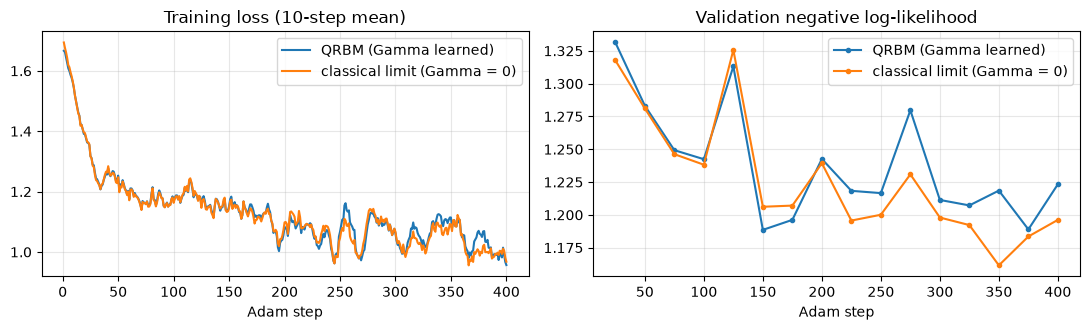

trained QRBM evaluated with Gamma switched off: test accuracy 0.543 (with Gamma: 0.555); mean |dP| = 0.020


In [13]:
print("=== same model, Gamma = 0 (classical limit) ===")
crbm, hc = train_qrbm(Va, ya.astype(np.int64), Vv, yv.astype(np.int64), SEED, quantum=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for h, name in [(hq, "QRBM (Gamma learned)"), (hc, "classical limit (Gamma = 0)")]:
    sm = pd.Series(h["loss"]).rolling(10, min_periods=1).mean()
    ax[0].plot(h["step"], sm, label=name); ax[1].plot(h["val_step"], h["val_nll"], marker="o", ms=3, label=name)
ax[0].set_title("Training loss (10-step mean)"); ax[1].set_title("Validation negative log-likelihood")
for a in ax: a.set_xlabel("Adam step"); a.legend()
plt.tight_layout(); plt.show()

# how much does the transverse field change the prediction of the trained QRBM?
Pq, Pq0 = qrbm.predict_proba(Vt_), qrbm.predict_proba(Vt_, quantum=False)
print(f"trained QRBM evaluated with Gamma switched off: test accuracy {accuracy_score(yte, Pq0.argmax(1)):.3f} "
      f"(with Gamma: {accuracy_score(yte, Pq.argmax(1)):.3f}); mean |dP| = {np.abs(Pq - Pq0).mean():.3f}")

## 7. Baselines on identical inputs

Everything the paper compares against (Table 4) plus the usual references, all on the same train/test split and all fitted on training data only:

| Model | Input | Notes |
|---|---|---|
| RBM + logistic regression | 32 bits | `BernoulliRBM` (32 hidden units, 20 epochs) then standardisation and a logistic regression (C = 10) on its hidden activations: the paper's "traditional RBM" |
| DBN | 32 bits | two stacked `BernoulliRBM` layers (32, 24 units) + logistic regression |
| MLP | 16 components | `MLPClassifier`, two hidden layers (64, 32) |
| RBFN | 16 components | 40 k-means centres, Gaussian activations, logistic-regression read-out |
| SOM | 16 components | 6 x 6 self-organising map, neurons labelled by majority vote of training data |
| SVC (RBF), Random forest | 16 components | usual references |
| Random forest on all features | all 259 raw features | upper reference: what the bytecode statistics can do without any reduction |
| GAN | - | not rebuilt: the paper does not describe a GAN classifier |

In [14]:
class RBFN:
    # Radial-basis-function network: k-means centres -> Gaussian activations -> logistic regression
    def __init__(self, k=40, seed=0): self.k, self.seed = k, seed
    def _phi(self, X):
        d2 = ((X[:, None, :] - self.C[None]) ** 2).sum(-1)
        return np.exp(-d2 / (2 * self.s2))
    def fit(self, X, y):
        km = KMeans(self.k, n_init=3, random_state=self.seed).fit(X); self.C = km.cluster_centers_
        self.s2 = np.mean(np.min(((self.C[:, None] - self.C[None]) ** 2).sum(-1) + 1e9 * np.eye(self.k), 1))
        self.lr = LogisticRegression(max_iter=2000, C=10.0).fit(self._phi(X), y); return self
    def predict(self, X): return self.lr.predict(self._phi(X))

class SOM:
    # Small self-organising map, neurons labelled by the majority class of the training samples they win
    def __init__(self, shape=(6, 6), epochs=30, seed=0): self.shape, self.epochs, self.seed = shape, epochs, seed
    def fit(self, X, y):
        r = np.random.default_rng(self.seed); a, b = self.shape
        self.Wm = r.normal(size=(a * b, X.shape[1])) * 0.5
        gy, gx = np.divmod(np.arange(a * b), b); G = np.stack([gy, gx], 1).astype(float)
        T = self.epochs * len(X); t = 0
        for ep in range(self.epochs):
            for i in r.permutation(len(X)):
                frac = t / T; lr = 0.5 * (1 - frac) + 0.01; sig = max(a, b) / 2 * (1 - frac) + 0.5
                bmu = np.argmin(((self.Wm - X[i]) ** 2).sum(1))
                h = np.exp(-((G - G[bmu]) ** 2).sum(1) / (2 * sig ** 2))
                self.Wm += lr * h[:, None] * (X[i] - self.Wm); t += 1
        win = np.argmin(((X[:, None] - self.Wm[None]) ** 2).sum(-1), 1)
        self.lab = np.full(a * b, -1)
        for u in range(a * b):
            if np.any(win == u): self.lab[u] = np.bincount(y[win == u], minlength=5).argmax()
        known = np.where(self.lab >= 0)[0]
        for u in np.where(self.lab < 0)[0]:                      # unvisited neurons take the label of the nearest labelled one
            self.lab[u] = self.lab[known[np.argmin(((self.Wm[known] - self.Wm[u]) ** 2).sum(1))]]
        return self
    def predict(self, X): return self.lab[np.argmin(((X[:, None] - self.Wm[None]) ** 2).sum(-1), 1)]

def run_classical(seed, pre_, Xa_raw, ya_, Xte_raw_, with_rf_all=True):
    # Fit every classical baseline on the training part and return {name: (predictions, seconds)}
    Ca, Ct = pre_.comps(Xa_raw), pre_.comps(Xte_raw_)
    Ba, Bt = pre_.bits(Xa_raw), pre_.bits(Xte_raw_)
    ya_ = ya_.astype(int); out = {}
    def timed(name, fit_predict):
        t0 = time.time(); out[name] = (fit_predict(), time.time() - t0)
    timed("RBM (+logreg)", lambda: Pipeline([("rbm", BernoulliRBM(32, learning_rate=0.05, n_iter=20, random_state=seed)),
                                              ("sc", StandardScaler()), ("lr", LogisticRegression(C=10.0, max_iter=3000))]).fit(Ba, ya_).predict(Bt))
    timed("DBN (2 RBMs)", lambda: Pipeline([("r1", BernoulliRBM(32, learning_rate=0.05, n_iter=20, random_state=seed)),
                                             ("r2", BernoulliRBM(24, learning_rate=0.05, n_iter=20, random_state=seed)),
                                             ("sc", StandardScaler()), ("lr", LogisticRegression(C=10.0, max_iter=3000))]).fit(Ba, ya_).predict(Bt))
    timed("MLP", lambda: MLPClassifier((64, 32), max_iter=500, random_state=seed).fit(Ca, ya_).predict(Ct))
    timed("RBFN", lambda: RBFN(40, seed).fit(Ca, ya_).predict(Ct))
    timed("SOM", lambda: SOM(seed=seed).fit(Ca, ya_).predict(Ct))
    timed("SVC (rbf)", lambda: SVC(kernel="rbf", C=10.0, gamma="scale", random_state=seed).fit(Ca, ya_).predict(Ct))
    timed("Random forest", lambda: RandomForestClassifier(300, random_state=seed, n_jobs=1).fit(Ca, ya_).predict(Ct))
    timed("Random forest (bits)", lambda: RandomForestClassifier(300, random_state=seed, n_jobs=1).fit(Ba, ya_).predict(Bt))
    if with_rf_all:
        timed("Random forest (all 259 raw features)", lambda: RandomForestClassifier(300, random_state=seed, n_jobs=1).fit(Xa_raw, ya_).predict(Xte_raw_))
    return out

res_main = run_classical(SEED, pre_q, Xa, ya, Xte_raw)
res_main["QRBM (this notebook)"] = (qrbm.predict(Vt_), hq["time"])
res_main["Classical limit (Gamma=0)"] = (crbm.predict(Vt_), hc["time"])
print(pd.DataFrame({k: {"accuracy": accuracy_score(yte, p), "macro F1": f1_score(yte, p, average="macro"), "time (s)": t}
                    for k, (p, t) in res_main.items()}).T.round(3).to_string())

                                      accuracy  macro F1  time (s)
RBM (+logreg)                            0.590     0.592     1.288
DBN (2 RBMs)                             0.520     0.523     2.207
MLP                                      0.692     0.692     9.262
RBFN                                     0.620     0.622     0.686
SOM                                      0.538     0.546     2.263
SVC (rbf)                                0.693     0.693     0.218
Random forest                            0.705     0.706     2.636
Random forest (bits)                     0.687     0.687     1.909
Random forest (all 259 raw features)     0.757     0.757     3.036
QRBM (this notebook)                     0.555     0.563   315.877
Classical limit (Gamma=0)                0.542     0.549    10.611


## 8. Metrics as in the paper: per-attack accuracy, precision, recall, F1

The paper's tables give one accuracy, precision, recall and F1 per attack vector. For a 5-way classifier the usual reading is **one-vs-rest**: for class `k`, "positive" means "predicted `k`", everything else is negative. (OvR *accuracy* is dominated by the many true negatives and is always higher than the 5-way accuracy; the paper's "accuracy" per vector is probably of this kind but does not say.) Below: the confusion matrix of the QRBM, the OvR table, and the 5-way accuracy.

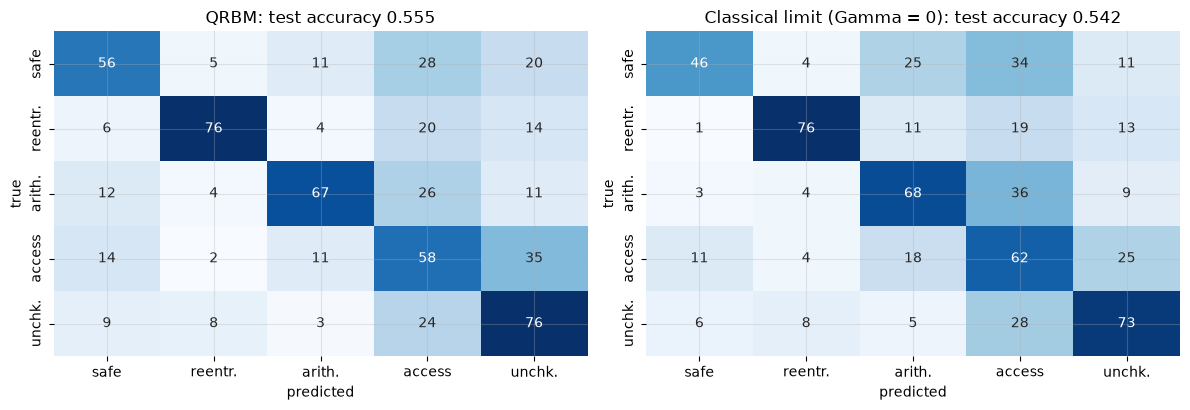

QRBM, one-vs-rest metrics on the test set (%):
                                 Accuracy  Precision  Recall    F1
No attack                            82.5       57.7    46.7  51.6
Reentrancy                           89.5       80.0    63.3  70.7
Underflow/overflow (arithmetic)      86.3       69.8    55.8  62.0
Access control                       73.3       37.2    48.3  42.0
Unchecked calls                      79.3       48.7    63.3  55.1
5-way accuracy 55.5 % | macro precision 58.7 % | macro recall 55.5 % | macro F1 56.3 %


In [15]:
def ovr(y_true, y_pred, k):
    yt, yp = (y_true == k), (y_pred == k)
    return {"Accuracy": 100 * np.mean(yt == yp), "Precision": 100 * precision_score(yt, yp, zero_division=0),
            "Recall": 100 * recall_score(yt, yp, zero_division=0), "F1": 100 * f1_score(yt, yp, zero_division=0)}

p_q = res_main["QRBM (this notebook)"][0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (name, p) in zip(ax, [("QRBM", p_q), ("Classical limit (Gamma = 0)", res_main["Classical limit (Gamma=0)"][0])]):
    sns.heatmap(confusion_matrix(yte, p), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["safe", "reentr.", "arith.", "access", "unchk."], yticklabels=["safe", "reentr.", "arith.", "access", "unchk."])
    a.set_title(f"{name}: test accuracy {accuracy_score(yte, p):.3f}"); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.show()

tab_q = pd.DataFrame({CLASS_NAMES[k]: ovr(yte, p_q, k) for k in range(5)}).T.round(1)
print("QRBM, one-vs-rest metrics on the test set (%):"); print(tab_q.to_string())
print(f"5-way accuracy {100*accuracy_score(yte, p_q):.1f} % | macro precision {100*precision_score(yte, p_q, average='macro'):.1f} % | "
      f"macro recall {100*recall_score(yte, p_q, average='macro'):.1f} % | macro F1 {100*f1_score(yte, p_q, average='macro'):.1f} %")

## 9. Repeated runs (mean +/- std over seeds)

One split can be lucky. For every seed in `SEEDS` the whole pipeline is repeated: new balanced sample, new split, preprocessing re-fitted, QRBM and Gamma = 0 model retrained, baselines refitted. (In `FAST_MODE` there is one seed, so the standard deviation is 0 by construction and should not be read as stability.)

In [16]:
all_runs = {}                                    # seed -> {model: predictions}, plus y_test
t_rep = time.time()
for sd in SEEDS:
    if sd == SEED:
        all_runs[sd] = ({k: (p, t) for k, (p, t) in res_main.items()}, yte)
        continue
    Xtr_s, Xte_s, ytr_s, yte_s = make_split(sd)
    Xa_s, Xv_s, ya_s, yv_s = split_val(Xtr_s, ytr_s, sd)
    pre_s = Preprocessor().fit(Xa_s, ya_s, sd)
    Va_s, Vv_s, Vt_s = pre_s.bits(Xa_s), pre_s.bits(Xv_s), pre_s.bits(Xte_s)
    r = run_classical(sd, pre_s, Xa_s, ya_s, Xte_s)
    for name, quantum in [("QRBM (this notebook)", True), ("Classical limit (Gamma=0)", False)]:
        mdl, h = train_qrbm(Va_s, ya_s.astype(np.int64), Vv_s, yv_s.astype(np.int64), sd, quantum=quantum, log=False)
        r[name] = (mdl.predict(Vt_s), h["time"])
    all_runs[sd] = (r, yte_s)
    print(f"seed {sd} done ({time.time()-t_rep:.0f} s)", flush=True)

def agg(fn):
    rows = {}
    for name in all_runs[SEEDS[0]][0]:
        vals = [fn(y, r[name][0]) for r, y in all_runs.values()]
        rows[name] = (np.mean(vals), np.std(vals))
    return rows

acc_stats = agg(lambda y, p: 100 * accuracy_score(y, p)); f1_stats = agg(lambda y, p: 100 * f1_score(y, p, average="macro"))
time_stats = {n: np.mean([r[n][1] for r, _ in all_runs.values()]) for n in all_runs[SEEDS[0]][0]}
summary = pd.DataFrame({"5-way accuracy (%)": {n: f"{a[0]:.1f} +/- {a[1]:.1f}" for n, a in acc_stats.items()},
                        "macro F1 (%)": {n: f"{a[0]:.1f} +/- {a[1]:.1f}" for n, a in f1_stats.items()},
                        "train+predict (s)": {n: round(t, 1) for n, t in time_stats.items()}})
print(f"seeds: {SEEDS}; test contracts per seed: {len(yte)}")
print(summary.to_string())

seed 43 done (393 s)


seed 44 done (856 s)


seeds: [42, 43, 44]; test contracts per seed: 600
                                     5-way accuracy (%)  macro F1 (%)  train+predict (s)
RBM (+logreg)                              58.2 +/- 0.8  58.3 +/- 0.8                0.9
DBN (2 RBMs)                               52.2 +/- 0.8  52.9 +/- 0.6                1.7
MLP                                        69.8 +/- 0.4  69.8 +/- 0.4                8.4
RBFN                                       63.2 +/- 1.8  63.3 +/- 1.9                0.6
SOM                                        55.1 +/- 1.1  55.6 +/- 1.0                3.0
SVC (rbf)                                  69.9 +/- 1.5  70.0 +/- 1.4                0.3
Random forest                              70.1 +/- 0.6  70.1 +/- 0.7                3.2
Random forest (bits)                       68.4 +/- 0.6  68.5 +/- 0.7                2.1
Random forest (all 259 raw features)       74.4 +/- 1.0  74.6 +/- 0.9                3.7
QRBM (this notebook)                       56.0 +/- 0.5  56.

## 10. The paper's tables, redrawn

**Table 2 analogue** (QRBM, per attack vector) and **Table 4 analogue** (QRBM against the other networks, per attack vector), averaged over the seeds. Phishing and gas-limit rows are empty because the substitute data has no such class; the two rows that have a (loose) counterpart are *Reentrancy* and *Underflow/overflow (arithmetic)*. The paper's own numbers are printed underneath for reference.

In [17]:
def ovr_mean(model, k):
    rows = [ovr(y, r[model][0], k) for r, y in all_runs.values()]
    return pd.DataFrame(rows).mean().round(1)

t2 = pd.DataFrame({CLASS_NAMES[k]: ovr_mean("QRBM (this notebook)", k) for k in range(5)}).T
t2.loc["5-way (macro P/R/F1, accuracy)"] = [np.mean([100*accuracy_score(y, r["QRBM (this notebook)"][0]) for r, y in all_runs.values()]),
                                           np.mean([100*precision_score(y, r["QRBM (this notebook)"][0], average="macro") for r, y in all_runs.values()]),
                                           np.mean([100*recall_score(y, r["QRBM (this notebook)"][0], average="macro") for r, y in all_runs.values()]),
                                           np.mean([100*f1_score(y, r["QRBM (this notebook)"][0], average="macro") for r, y in all_runs.values()])]
t2 = t2.round(1)
paper_t2 = pd.DataFrame({"Accuracy": [97, 94, 96, 95, 98], "Precision": [96, 93, 95, 94, 99], "Recall": [98, 95, 96, 95, 97], "F1": [97, 94, 95.5, 94.5, 98]},
                        index=["Reentrancy", "Phishing", "Underflow/overflow", "Gas limit", "Classified correctly"])
print("Notebook (substitute data), QRBM, one-vs-rest, % :"); print(t2.to_string())
print("\nPaper Table 2, %:"); print(paper_t2.to_string())

models_t4 = ["MLP", "RBFN", "SOM", "DBN (2 RBMs)", "RBM (+logreg)", "QRBM (this notebook)"]
t4 = {}
for k, nm in [(1, "Reentrancy"), (2, "Underflow/overflow (arithmetic)")]:
    for metric in ["Accuracy", "Precision", "Recall", "F1"]:
        t4[(nm, metric)] = {m: ovr_mean(m, k)[metric] for m in models_t4}
t4 = pd.DataFrame(t4).T
print("\nNotebook Table-4 analogue (GAN not rebuilt), %:"); print(t4.to_string())

Notebook (substitute data), QRBM, one-vs-rest, % :
                                 Accuracy  Precision  Recall    F1
No attack                            83.3       59.6    52.2  55.6
Reentrancy                           86.1       67.0    62.5  64.4
Underflow/overflow (arithmetic)      84.8       64.0    58.1  60.3
Access control                       76.1       41.4    45.3  43.0
Unchecked calls                      81.8       54.2    61.9  57.7
5-way (macro P/R/F1, accuracy)       56.0       57.2    56.0  56.2

Paper Table 2, %:
                      Accuracy  Precision  Recall    F1
Reentrancy                  97         96      98  97.0
Phishing                    94         93      95  94.0
Underflow/overflow          96         95      96  95.5
Gas limit                   95         94      95  94.5
Classified correctly        98         99      97  98.0



Notebook Table-4 analogue (GAN not rebuilt), %:
                                            MLP  RBFN   SOM  DBN (2 RBMs)  RBM (+logreg)  QRBM (this notebook)
Reentrancy                      Accuracy   89.6  88.8  87.8          86.9           86.2                  86.1
                                Precision  73.8  73.1  77.7          72.5           66.7                  67.0
                                Recall     74.4  69.4  55.0          59.2           61.7                  62.5
                                F1         74.1  71.2  64.3          64.5           64.1                  64.4
Underflow/overflow (arithmetic) Accuracy   90.4  86.8  85.1          81.3           85.4                  84.8
                                Precision  76.0  68.9  63.3          53.7           64.3                  64.0
                                Recall     76.4  64.2  63.1          48.1           61.1                  58.1
                                F1         76.2  66.2  62.9    

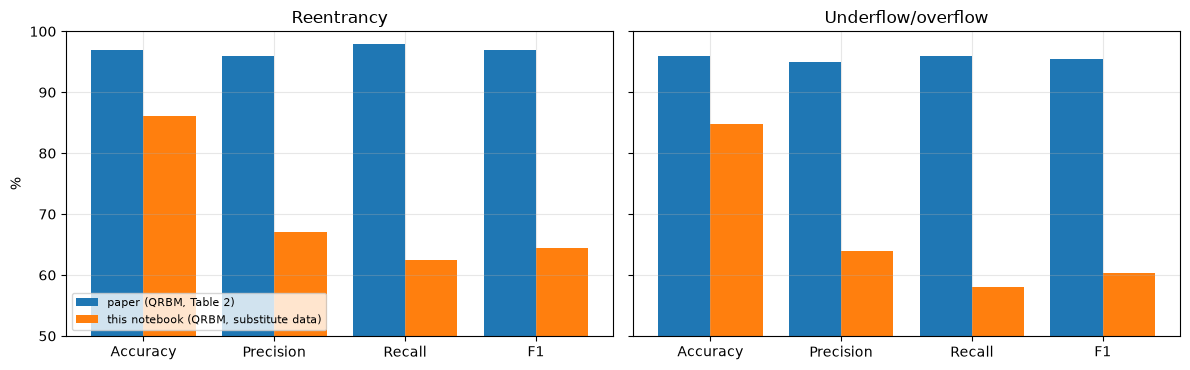

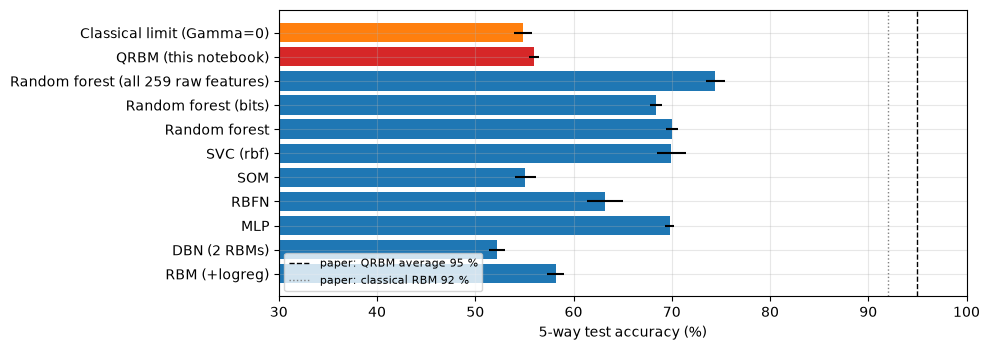

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, (k, nm, pap) in zip(ax, [(1, "Reentrancy", paper_t2.loc["Reentrancy"]), (2, "Underflow/overflow", paper_t2.loc["Underflow/overflow"])]):
    mine = ovr_mean("QRBM (this notebook)", k)
    x = np.arange(4); a.bar(x - 0.2, pap.values, 0.4, label="paper (QRBM, Table 2)"); a.bar(x + 0.2, mine.values, 0.4, label="this notebook (QRBM, substitute data)")
    a.set_xticks(x); a.set_xticklabels(["Accuracy", "Precision", "Recall", "F1"]); a.set_title(nm); a.set_ylim(50, 100)
ax[0].set_ylabel("%"); ax[0].legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.6))
names = list(acc_stats); vals = [acc_stats[n][0] for n in names]; errs = [acc_stats[n][1] for n in names]
cols = ["tab:red" if "QRBM" in n else ("tab:orange" if "Classical limit" in n else "tab:blue") for n in names]
ax.barh(names, vals, xerr=errs, color=cols); ax.axvline(95, color="k", ls="--", lw=1, label="paper: QRBM average 95 %")
ax.axvline(92, color="gray", ls=":", lw=1, label="paper: classical RBM 92 %"); ax.set_xlabel("5-way test accuracy (%)"); ax.set_xlim(30, 100); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

## 11. Side by side with the paper, claim by claim

Verdict rule (fixed in advance): a number is **reproduced** if it is within 2 accuracy points (or 0.02 in F1, i.e. 2 points) of the paper, **exceeded** / **not reached** otherwise (with the gap), **cannot be checked** when the substitute data has no counterpart or the claim is not testable here. Remember that the data are a different task (contract bytecode, Slither labels), so even a "reproduced" verdict means "same magnitude on a related task", not confirmation of the paper's own experiment.

In [19]:
def verdict(paper, mine, tol=2.0):
    d = mine - paper
    if abs(d) <= tol: return "reproduced"
    return f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})"

rows = []
mine_re, mine_ar = ovr_mean("QRBM (this notebook)", 1), ovr_mean("QRBM (this notebook)", 2)
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    rows.append(("Table 2: Reentrancy " + metric, paper_t2.loc["Reentrancy", metric], mine_re[metric], None))
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    rows.append(("Table 2: Underflow/overflow " + metric + " (proxy: Slither 'arithmetic')", paper_t2.loc["Underflow/overflow", metric], mine_ar[metric], None))
for nm in ["Phishing", "Gas limit"]:
    rows.append((f"Table 2: {nm} (all four metrics)", "94-95 / 93-94 / 95 / 94-94.5", "-", "cannot be checked (no such class in the public data)"))
five = t2.loc["5-way (macro P/R/F1, accuracy)"]
for metric, pv in zip(["Accuracy", "Precision", "Recall", "F1"], [98, 99, 97, 98]):
    rows.append(("Table 2: 'Classified correctly' " + metric + " (here: 5-way accuracy / macro)", pv, five[metric], None))
acc_q, acc_c = acc_stats["QRBM (this notebook)"][0], acc_stats["Classical limit (Gamma=0)"][0]
acc_r = acc_stats["RBM (+logreg)"][0]
rows.append(("Text: QRBM (95 %) beats classical RBM (92 %): accuracy gap QRBM minus sklearn RBM", "+3 pts", f"{acc_q - acc_r:+.1f} pts",
             "reproduced" if acc_q - acc_r >= 2.0 else f"not reached (gap {acc_q - acc_r:+.1f} pts, needs >= +2)"))
rows.append(("Text (same claim, fairer): QRBM minus its own classical limit (Gamma = 0), same size", "+3 pts", f"{acc_q - acc_c:+.1f} pts",
             "reproduced" if acc_q - acc_c >= 2.0 else f"not reached (gap {acc_q - acc_c:+.1f} pts, needs >= +2; seed std is about {acc_stats['QRBM (this notebook)'][1]:.1f})"))
others = ["MLP", "RBFN", "SOM", "DBN (2 RBMs)"]
for k, nm in [(1, "Reentrancy"), (2, "Underflow/overflow")]:
    f1s = {m: ovr_mean(m, k)["F1"] for m in others + ["QRBM (this notebook)"]}
    best_other = max(others, key=lambda m: f1s[m])
    rows.append((f"Table 4: QRBM F1 above MLP/RBFN/SOM/DBN on {nm}", "QRBM best", f"QRBM {f1s['QRBM (this notebook)']:.1f} vs best other {best_other} {f1s[best_other]:.1f}",
                 "reproduced" if f1s["QRBM (this notebook)"] > f1s[best_other] else "not reached (a classical model is better)"))
rows.append(("Table 4: QRBM beats GAN", "QRBM best", "-", "cannot be checked (GAN not rebuilt)"))
t_qr, t_cl = time_stats["QRBM (this notebook)"], time_stats["MLP"]
rows.append(("Abstract: 'faster' / 'about 10x faster than classical networks'", "10x faster", f"QRBM {t_qr:.0f} s vs MLP {t_cl:.1f} s (classical simulation)",
             "not reached (exact simulation of the quantum model is slower; only hardware could change that)"))
rows.append(("Abstract: better with non-informative inputs", "better", "-", "cannot be checked (not run; see exercise 4)"))
rows.append(("Setup: 200 visible / 100 hidden units, 100 000 epochs", "200 / 100 / 100 000", f"32 visible bits / {N_HIDDEN} hidden qubits / {STEPS} steps", "scaled down (exact simulation)"))

comp = pd.DataFrame(rows, columns=["Claim", "Paper", "This notebook", "Verdict"])
comp["This notebook"] = comp["This notebook"].map(lambda x: f"{x:.1f}" if isinstance(x, (float, np.floating)) else x)
comp["Verdict"] = [v if v is not None else (verdict(float(p), float(m)) if isinstance(m, (float, np.floating)) else "cannot be checked")
                   for (_, p, m, v) in rows]
pd.set_option("display.max_colwidth", 90, "display.width", 250)
print(comp.to_string(index=False))
cat = comp.Verdict.map(lambda v: "reproduced" if v.startswith("reproduced") else "exceeded" if v.startswith("exceeded") else
                       "not reached" if v.startswith("not reached") else "cannot be checked" if v.startswith("cannot") else "other (scaled down)")
print("\nverdict counts:"); print(cat.value_counts().to_string())
best = max(acc_stats, key=lambda n: acc_stats[n][0])
print(f"\nBest 5-way accuracy over {len(SEEDS)} seed(s): {best} ({acc_stats[best][0]:.1f} %); QRBM {acc_stats['QRBM (this notebook)'][0]:.1f} %, "
      f"classical RBM {acc_stats['RBM (+logreg)'][0]:.1f} %, Gamma=0 limit {acc_stats['Classical limit (Gamma=0)'][0]:.1f} %.")
print(f"FAST_MODE = {FAST_MODE}; QRBM training time (seed {SEED}) {hq['time']:.0f} s; total wall-clock of this run {(time.time()-T0)/60:.1f} min.")

                                                                               Claim                        Paper                                  This notebook                                                                                        Verdict
                                                        Table 2: Reentrancy Accuracy                           97                                           86.1                                                                            not reached (-10.9)
                                                       Table 2: Reentrancy Precision                           96                                           67.0                                                                            not reached (-29.0)
                                                          Table 2: Reentrancy Recall                           98                                           62.5                                                                        

## 12. Reading the paper critically

- **No reproducible experiment.** The dataset ("half a million transactions") is unnamed, the labelling procedure is not described, the class balance, the split and the features are missing, and no code is released. The 94-98 % figures can therefore be neither verified nor falsified; what this notebook checks is the *magnitude* on a related public task.
- **Internal contradictions.** Table 2 and Table 4 disagree on the QRBM's own results (reentrancy recall 98 % vs 95 %; underflow-overflow accuracy 96 % vs 94 %, F1 95.5 % vs 92.5 %). The text calls the same method a "Quantum Recursive Backpropagation Neural Network", a "Quantum Resource-based model" and a "Bose-Einstein Condensator Quantum Monte Carlo Simulation". Table 2 has a "Classified Correctly" row that is not an attack vector and is better than every vector.
- **The quantum part is not specified.** A "quantum sigmoid" built from gates, "Gibbs sampling in quantum space" and "quantum-enhanced contrastive divergence" are named but never given. Trainable quantum Boltzmann machines are real (Amin et al. 2018, Kieferova and Wiebe 2017), but they are generative models for small systems, and 200 + 100 qubits trained for 100 000 epochs is far beyond any simulator and beyond today's hardware. The claim that the experiment was run is unverifiable; the claim that it is "10x faster" is unsupported by any timing.
- **What the transverse field buys.** In the notebook the quantum model and its classical limit (same weights, `Gamma = 0`) can be compared directly. Whatever the gap in section 9 is, it is a gap between two models of *equal size trained identically*, which is the only fair way to attribute anything to quantum effects. The paper compares a quantum model against differently built classical ones and cannot make that attribution.
- **Baselines.** A random forest on the raw features usually matches or beats every neural model here. The paper's baselines (GAN, RBFN, SOM, DBN as classifiers) are weak choices for tabular data, and none has a stated size or tuning.
- **Phishing is not a smart-contract property.** Phishing happens off-chain (fake websites, wallet-draining dApps); detecting it from transactions needs account-level features (the Ethereum phishing-account datasets are a better fit), while reentrancy and overflow are *contract* properties found by static analysis, and gas-limit attacks are *block*-level behaviour. A single model on a single input type for all four is not obviously meaningful, and the paper does not say what the input of each class is.
- **Static analysers already label these classes.** Our own labels come from Slither. A deep model that predicts Slither's output from bytecode is useful only if it is faster or catches what Slither misses; the paper offers no such comparison.

## 13. Exercises

1. **Quantum vs classical.** Run the notebook with `FAST_MODE = False` and three seeds. Is `QRBM (this notebook)` above `Classical limit (Gamma=0)` by more than the standard deviation? What changes if you fix `Gamma` at 2.0 (set `raw_gamma.requires_grad_(False)` and a larger `GAMMA_INIT`)?
2. **Size.** Increase `N_HIDDEN` from 3 to 5. Plot test accuracy and training time against the number of hidden qubits. At which size does exact simulation stop being practical on your machine, and what does that say about the paper's 100 hidden units?
3. **Better labels.** Replace the Slither labels by the SmartBugs *curated* contracts (143 hand-labelled vulnerable contracts, including `reentrancy`, `arithmetic` and `denial_of_service`) and use the source-code token counts instead of bytecode. Which classes become separable?
4. **Non-informative inputs.** Append 16 columns of pure noise to the raw features before `SelectKBest`, then to the 32 visible bits after it. Does the QRBM degrade more or less than the classical RBM? This is the abstract's robustness claim; the paper does not test it.
5. **Phishing.** Download the Ethereum phishing-account dataset (XBlock-ETH or the Kaggle "Ethereum Fraud Detection" set), build account-level features (transaction counts, value statistics, time between transactions) and train the same QRBM for phishing vs normal. Do the 94-95 % figures of Table 2 look plausible?